<a href="https://colab.research.google.com/github/vigneshwaranmanikandan/data-science/blob/main/movie_recommendation_systema_using_knn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix

In [58]:
movies = pd.read_csv(r"/content/movies.csv")

In [59]:
ratings = pd.read_csv(r"/content/ratings.csv")

In [60]:
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [61]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [62]:
print("Movies shape: ", movies.shape)
print("Ratings shape: ", ratings.shape)

Movies shape:  (9742, 3)
Ratings shape:  (100836, 4)


In [63]:
movies.info()
ratings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  9742 non-null   int64 
 1   title    9742 non-null   object
 2   genres   9742 non-null   object
dtypes: int64(1), object(2)
memory usage: 228.5+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


In [64]:
print("Movies missing values:")
print(movies.isnull().sum())
print("Rating missing values:")
print(ratings.isnull().sum())

Movies missing values:
movieId    0
title      0
genres     0
dtype: int64
Rating missing values:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


In [65]:
print("Total Movies: ", movies['movieId'].nunique())
print("Total Users: ", ratings['userId'].nunique())
print("Total Ratings: ", ratings.shape[0])

Total Movies:  9742
Total Users:  610
Total Ratings:  100836


In [66]:
ratings.describe()

,userId,movieId,rating,timestamp
count,100836.000000,100836.000000,100836.000000,1.008360e+05
mean,326.127564,19435.295718,3.501557,1.205946e+09
std,182.618491,35530.987199,1.042529,2.162610e+08
min,1.000000,1.000000,0.500000,8.281246e+08
25%,177.000000,1199.000000,3.000000,1.019124e+09
50%,325.000000,2991.000000,3.500000,1.186087e+09
75%,477.000000,8122.000000,4.000000,1.435994e+09
max,610.000000,193609.000000,5.000000,1.537799e+09


In [67]:
ratings['rating'].value_counts().sort_index()

,count
rating,
0.5,1370
1.0,2811
1.5,1791
2.0,7551
2.5,5550
3.0,20047
3.5,13136
4.0,26818
4.5,8551


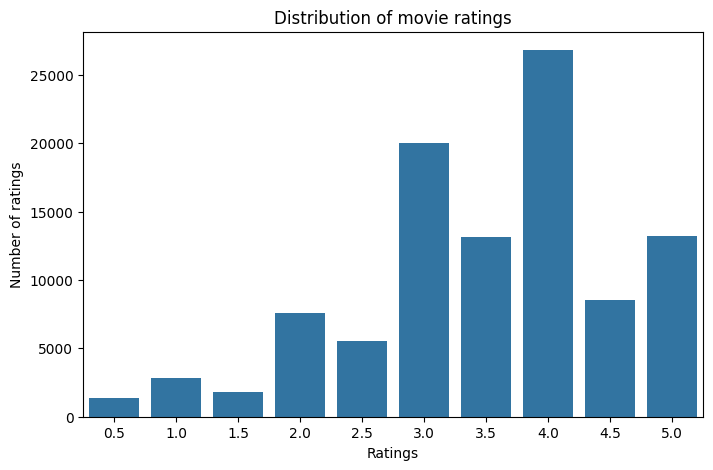

In [68]:
plt.figure(figsize=(8,5))
sns.countplot(data=ratings, x='rating')
plt.title("Distribution of movie ratings")
plt.xlabel("Ratings")
plt.ylabel("Number of ratings")
plt.show()

In [69]:
movie_counts = ratings.groupby('movieId')['rating'].count()
movie_counts = movie_counts.sort_values(ascending=False)
movie_counts

,rating
movieId,
356,329
318,317
296,307
593,279
2571,278
...,...
190207,1
190183,1
189713,1


In [70]:
popular_movies = pd.merge(movie_counts.rename('rating_count'), movies, on='movieId')
popular_movies.head(10)

,movieId,rating_count,title,genres
0,356,329,Forrest Gump (1994),Comedy|Drama|Romance|War
1,318,317,"Shawshank Redemption, The (1994)",Crime|Drama
2,296,307,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller
3,593,279,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller
4,2571,278,"Matrix, The (1999)",Action|Sci-Fi|Thriller
5,260,251,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi
6,480,238,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller
7,110,237,Braveheart (1995),Action|Drama|War
8,589,224,Terminator 2: Judgment Day (1991),Action|Sci-Fi
9,527,220,Schindler's List (1993),Drama|War


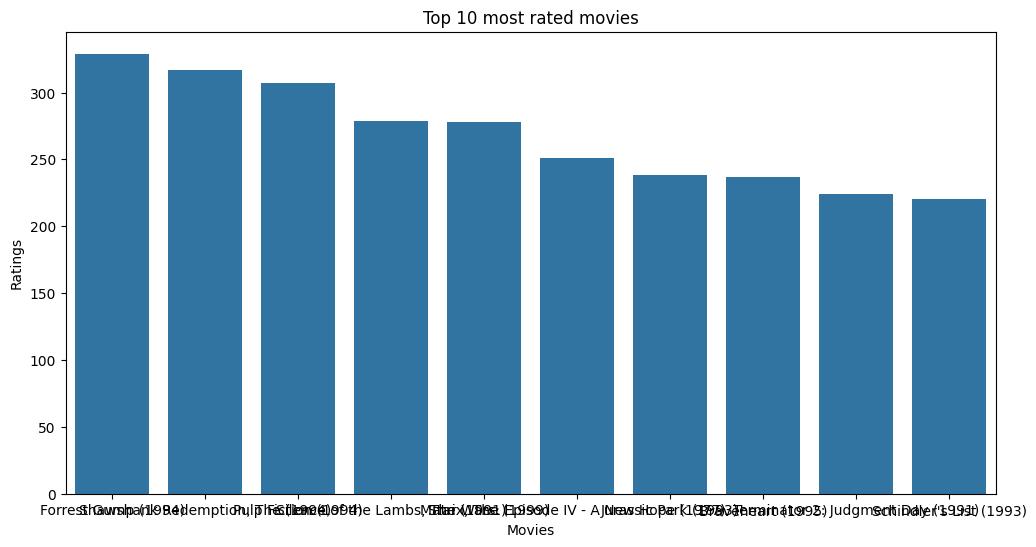

In [71]:
top_movies = popular_movies.head(10)
plt.figure(figsize=(12,6))
sns.barplot(data=top_movies, x='title', y='rating_count')
plt.title("Top 10 most rated movies")
plt.xlabel("Movies")
plt.ylabel("Ratings")
plt.show()

In [72]:
avg_movie_ratings = ratings.groupby('movieId')['rating'].mean()
avg_movie_ratings = avg_movie_ratings.sort_values(ascending=False)
avg_movie_ratings.head(10)

,rating
movieId,
187717,5.0
6983,5.0
5328,5.0
95843,5.0
3941,5.0
3940,5.0
3939,5.0
7815,5.0
162414,5.0


In [73]:
user_activity = ratings.groupby('userId')['rating'].count()
user_activity.describe()

,rating
count,610.000000
mean,165.304918
std,269.480584
min,20.000000
25%,35.000000
50%,70.500000
75%,168.000000
max,2698.000000


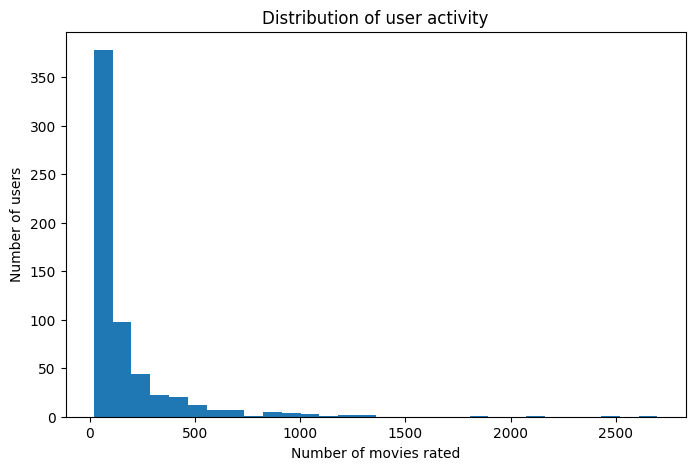

In [74]:
plt.figure(figsize=(8,5))
plt.hist(user_activity, bins=30)
plt.title("Distribution of user activity")
plt.xlabel("Number of movies rated")
plt.ylabel("Number of users")
plt.show()

In [75]:
genres = movies['genres'].str.split('|').explode()
genre_counts = genres.value_counts()
genre_counts

,count
genres,
Drama,4361
Comedy,3756
Thriller,1894
Action,1828
Romance,1596
Adventure,1263
Crime,1199
Sci-Fi,980
Horror,978


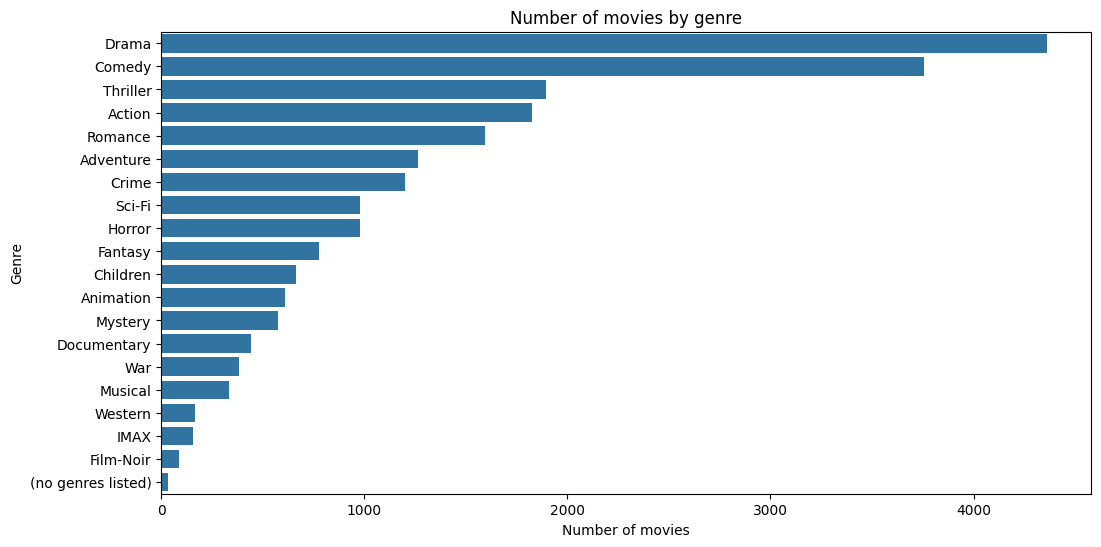

In [76]:
plt.figure(figsize=(12,6))
sns.barplot(x=genre_counts.values, y = genre_counts.index)
plt.title("Number of movies by genre")
plt.xlabel("Number of movies")
plt.ylabel("Genre")
plt.show()

In [77]:
ratings.duplicated().sum()

np.int64(0)

In [78]:
movies['movieId'].duplicated().sum()

np.int64(0)

In [79]:
movies.isnull().sum()
ratings.isnull().sum()

,0
userId,0
movieId,0
rating,0
timestamp,0


In [80]:
print(movies.dtypes)
print(ratings.dtypes)

movieId     int64
title      object
genres     object
dtype: object
userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object


In [81]:
df = pd.merge(ratings, movies, on='movieId', how ='inner')

In [82]:
df.head()

,userId,movieId,rating,timestamp,title,genres
0,1,1,4.0,964982703,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,1,3,4.0,964981247,Grumpier Old Men (1995),Comedy|Romance
2,1,6,4.0,964982224,Heat (1995),Action|Crime|Thriller
3,1,47,5.0,964983815,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
4,1,50,5.0,964982931,"Usual Suspects, The (1995)",Crime|Mystery|Thriller


In [83]:
df.shape

(100836, 6)

In [84]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 6 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
 4   title      100836 non-null  object 
 5   genres     100836 non-null  object 
dtypes: float64(1), int64(3), object(2)
memory usage: 4.6+ MB


In [85]:
user_rating_counts = df.groupby('userId')['rating'].count()
user_rating_counts.head()

,rating
userId,
1,232
2,29
3,39
4,216
5,44


In [86]:
movie_rating_counts = df.groupby('movieId')['rating'].count()
movie_rating_counts.head()

,rating
movieId,
1,215
2,110
3,52
4,7
5,49


In [87]:
popular_movie_ids = movie_rating_counts[movie_rating_counts >= 20].index

In [88]:
df_filtered = df[df['movieId'].isin(popular_movie_ids)]

In [89]:
print("Original records: ", df.shape)
print("Filtered records: ", df_filtered.shape)

print("Original Movies: ", df['movieId'].nunique())
print("Filtered Movies: ", df_filtered['movieId'].nunique())

Original records:  (100836, 6)
Filtered records:  (67898, 6)
Original Movies:  9724
Filtered Movies:  1297


In [90]:
user_movie_matrix = df_filtered.pivot_table(index = 'userId', columns = 'title', values = 'rating')

In [91]:
user_movie_matrix.head(10)

title,(500) Days of Summer (2009),10 Things I Hate About You (1999),101 Dalmatians (1996),101 Dalmatians (One Hundred and One Dalmatians) (1961),12 Angry Men (1957),13 Going on 30 (2004),"13th Warrior, The (1999)",1408 (2007),2001: A Space Odyssey (1968),2012 (2009),...,Young Frankenstein (1974),Young Guns (1988),Zack and Miri Make a Porno (2008),Zodiac (2007),Zombieland (2009),Zoolander (2001),Zootopia (2016),eXistenZ (1999),xXx (2002),¡Three Amigos! (1986)
userId,,,,,,,,,,,,,,,,,,,,,
1,NaN,NaN,NaN,NaN,NaN,NaN,4.0,NaN,NaN,NaN,...,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN


In [92]:
user_movie_matrix.shape

(610, 1297)

In [93]:
total_cells = user_movie_matrix.size
filled_cells = user_movie_matrix.notna().sum().sum()
sparsity = (1-filled_cells/total_cells) * 100
print("Matrix sparsity: ", sparsity, "%")

Matrix sparsity:  91.41802646713096 %


In [94]:
movie_user_matrix= user_movie_matrix.T

In [95]:
movie_user_matrix.head()

userId,1,2,3,4,5,6,7,8,9,10,...,601,602,603,604,605,606,607,608,609,610
title,,,,,,,,,,,,,,,,,,,,,
(500) Days of Summer (2009),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.5
10 Things I Hate About You (1999),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,3.0,NaN,5.0,NaN,NaN,NaN,NaN,NaN
101 Dalmatians (1996),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,4.0,NaN,3.0,NaN,NaN,NaN,NaN,NaN
101 Dalmatians (One Hundred and One Dalmatians) (1961),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12 Angry Men (1957),NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN,NaN,NaN,...,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [96]:
movie_user_matrix.fillna(0, inplace=True)

In [97]:
movie_user_matrix.head()

userId,1,2,3,4,5,6,7,8,9,10,...,601,602,603,604,605,606,607,608,609,610
title,,,,,,,,,,,,,,,,,,,,,
(500) Days of Summer (2009),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.5
10 Things I Hate About You (1999),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,3.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0
101 Dalmatians (1996),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,4.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0
101 Dalmatians (One Hundred and One Dalmatians) (1961),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
12 Angry Men (1957),0.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [98]:
from scipy.sparse import csr_matrix
sparse_matrix = csr_matrix(movie_user_matrix)

In [99]:
print(sparse_matrix.shape)
print(type(sparse_matrix))

(1297, 610)
<class 'scipy.sparse._csr.csr_matrix'>


In [100]:
knn = NearestNeighbors(metric='cosine', algorithm='brute',n_neighbors=6)

In [101]:
knn.fit(sparse_matrix)

NearestNeighbors(algorithm='brute', metric='cosine', n_neighbors=6)

In [102]:
movie_name = 'Toy Story (1995)'
movie_index = movie_user_matrix.index.get_loc(movie_name)
print(movie_index)

1186


In [103]:
distances, indices = knn.kneighbors(sparse_matrix[movie_index], n_neighbors=6)

In [104]:
for i in range(1, len(indices[0])):
  print(movie_user_matrix.index[indices[0][i]],"Distance:", distances[0][i])

Toy Story 2 (1999) Distance: 0.4273987396802844
Jurassic Park (1993) Distance: 0.4343631959138433
Independence Day (a.k.a. ID4) (1996) Distance: 0.43573830647233425
Star Wars: Episode IV - A New Hope (1977) Distance: 0.4426118294200634
Forrest Gump (1994) Distance: 0.4529040920598262


In [105]:
def recommend_movies(movie_name):
  if movie_name not in movie_user_matrix.index:
    print("Movie not found in the dataset")

  movie_index = movie_user_matrix.index.get_loc(movie_name)
  distance, indices = knn.kneighbors(sparse_matrix[movie_index], n_neighbors=6)
  recommendations=[]

  for i in range(1, len(indices[0])):
     recommendations.append({
            'Movie': movie_user_matrix.index[indices[0][i]],
            'Cosine Distance': distances[0][i],
            'Cosine Similarity': 1 - distances[0][i]
      })

  return pd.DataFrame(recommendations)

In [106]:
recommend_movies('Toy Story (1995)')

,Movie,Cosine Distance,Cosine Similarity
0,Toy Story 2 (1999),0.427399,0.572601
1,Jurassic Park (1993),0.434363,0.565637
2,Independence Day (a.k.a. ID4) (1996),0.435738,0.564262
3,Star Wars: Episode IV - A New Hope (1977),0.442612,0.557388
4,Forrest Gump (1994),0.452904,0.547096


In [107]:
from sklearn.model_selection import train_test_split

train_parts = []
test_parts = []

for userId, group in df_filtered.groupby('userId'):
  if len(group) < 2:
    continue
  train, test = train_test_split(group, test_size=0.2, random_state=42)
  train_parts.append(train)
  test_parts.append(test)

train_df = pd.concat(train_parts)
test_df = pd.concat(test_parts)

print("Training shape: ", train_df.shape)
print("Testing shape: ", test_df.shape)

Training shape:  (54082, 6)
Testing shape:  (13816, 6)


In [108]:
train_matrix = train_df.pivot_table(index='userId',columns='title',values='rating')
movie_user_train = train_matrix.T.fillna(0)
train_sparse = csr_matrix(movie_user_train.values)

In [109]:
knn_eval = NearestNeighbors(metric='cosine',algorithm='brute',n_neighbors=11)
knn_eval.fit(train_sparse)

NearestNeighbors(algorithm='brute', metric='cosine', n_neighbors=11)

In [110]:
def recommend_for_user(user_id, n=10):
    if user_id not in train_matrix.index:
        return []
    user_ratings = train_matrix.loc[user_id]
    liked_movies = user_ratings[user_ratings >= 4].index

    if len(liked_movies) == 0:
        return []

    scores = {}

    for movie in liked_movies:
        movie_index = movie_user_train.index.get_loc(movie)
        distances, indices = knn_eval.kneighbors(train_sparse[movie_index],n_neighbors=11)

        for distance, index in zip(distances[0], indices[0]):
            similar_movie = movie_user_train.index[index]
            if similar_movie in user_ratings.dropna().index:
                continue
            similarity = 1 - distance
            scores[similar_movie] = (scores.get(similar_movie, 0) + similarity)

    ranked_movies = sorted(scores.items(),key=lambda x: x[1],reverse=True)

    return [movie for movie, score in ranked_movies[:n]]

In [111]:
recommend_for_user(1, 20)

['RoboCop (1987)',
 'Indiana Jones and the Temple of Doom (1984)',
 'Gremlins (1984)',
 'Pulp Fiction (1994)',
 'Escape from New York (1981)',
 "Ferris Bueller's Day Off (1986)",
 'For Your Eyes Only (1981)',
 'Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981)',
 'Peter Pan (1953)',
 'Aliens (1986)',
 'Jurassic Park (1993)',
 'Cinderella (1950)',
 'Terminator, The (1984)',
 'Sixth Sense, The (1999)',
 'Godfather, The (1972)',
 'Mad Max Beyond Thunderdome (1985)',
 'Memento (2000)',
 'Magnolia (1999)',
 'Shawshank Redemption, The (1994)',
 'Robin Hood (1973)']